# Drzewo decyzyjne na zbiorze Iris

**Plan notatnika:**
1. Dane
2. Podział na zbiór treningowy i testowy
3. Wpływ głębokości drzewa na granice decyzyjne
4. Drzewo na wszystkich cechach
5. Predykcja dla nowego kwiatu
6. Podsumowanie

Zbiór **Iris** opisuje 150 kwiatów irysa trzech gatunków (po 50 sztuk) czterema pomiarami (w cm): długością i szerokością **działki kielicha** (`sepal`) oraz **płatka** (`petal`). Zadanie: rozpoznać gatunek na podstawie pomiarów (klasyfikacja na 3 klasy).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris
from sklearn.dummy import DummyClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

## 1. Dane

In [3]:
iris = load_iris(as_frame=True)
df = iris.frame.rename(columns={
    'sepal length (cm)': 'sepal_length', 'sepal width (cm)': 'sepal_width',
    'petal length (cm)': 'petal_length', 'petal width (cm)': 'petal_width',
})
nazwy_klas = list(iris.target_names)

print('Kształt danych:', df.shape)
print('Gatunki:', nazwy_klas)
df.head()

Kształt danych: (150, 5)
Gatunki: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
df['target'].value_counts().sort_index()

target
0    50
1    50
2    50
Name: count, dtype: int64

Klasy są idealnie zbalansowane (po 50 kwiatów), a zmienna celu `target` koduje gatunki: 0 – setosa, 1 – versicolor, 2 – virginica. Zobaczmy, jak wyglądają:

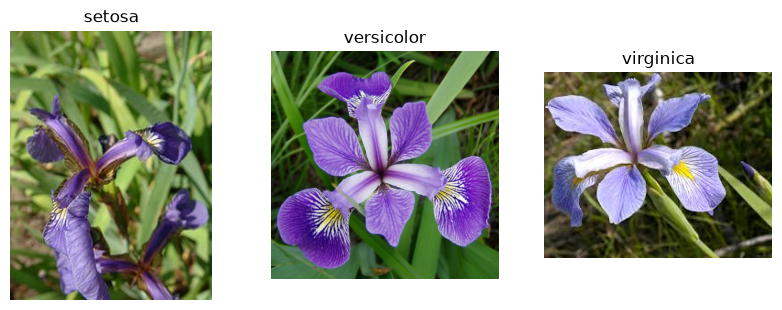

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, gatunek in zip(axes, nazwy_klas):
    ax.imshow(mpimg.imread(f'../obrazki/4.1_iris_{gatunek}.jpg'))
    ax.set_title(gatunek)
    ax.axis('off')
plt.show()

## 2. Podział na zbiór treningowy i testowy

Model oceniamy na danych, których nie widział podczas uczenia. Parametr `stratify` zachowuje proporcje gatunków w obu zbiorach, a `random_state` daje powtarzalny podział.

Na początku użyjemy tylko **dwóch cech** (`sepal_length`, `sepal_width`), bo wtedy możemy narysować granice decyzyjne na płaszczyźnie.

In [6]:
cechy_2d = ['sepal_length', 'sepal_width']
X = df[cechy_2d]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print('Zbiór treningowy:', X_train.shape, '  testowy:', X_test.shape)

Zbiór treningowy: (105, 2)   testowy: (45, 2)


In [7]:
# baseline: model, który zawsze przewiduje klasę najczęstszą (przy 3 równych klasach ~ 1/3)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f'Accuracy baseline na zbiorze testowym: {baseline.score(X_test, y_test):.3f}')

Accuracy baseline na zbiorze testowym: 0.333


Baseline ma około 33% trafności – tyle daje zgadywanie. Każdy sensowny model powinien być wyraźnie lepszy.

## 3. Wpływ głębokości drzewa na granice decyzyjne

Zaczynamy od najprostszego drzewa: `max_depth=1` (jeden podział, tzw. *pniak*).

/Users/tomasz/0.Szkolenia/ML_DL_Python [do przygotowania - potem zrobić z tego szablon na koniec]/.venv/lib/python3.13/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


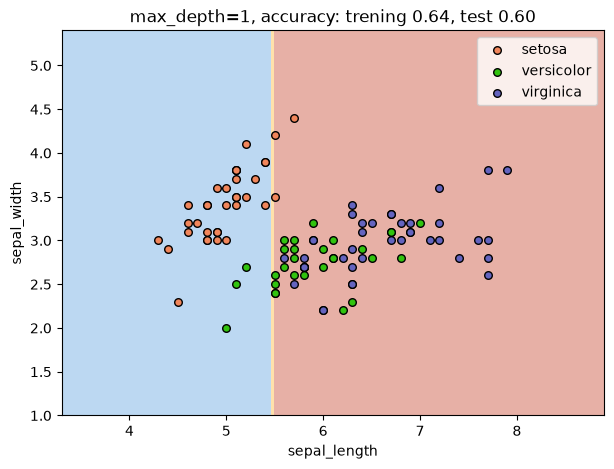

In [8]:
kolory = ['#f1865b', '#31c30f', '#6464bf']
cmap = ListedColormap(kolory)

def rysuj_granice(model, X, y, ax, tytul):
    """Rysuje obszary decyzyjne modelu oraz punkty danych."""
    DecisionBoundaryDisplay.from_estimator(model, X, response_method='predict', cmap=cmap, alpha=0.35, ax=ax)
    for klasa, nazwa in enumerate(nazwy_klas):
        maska = (y == klasa)
        ax.scatter(X[maska].iloc[:, 0], X[maska].iloc[:, 1], color=kolory[klasa], edgecolor='k', s=30, label=nazwa)
    ax.set_title(tytul)

pien = DecisionTreeClassifier(max_depth=1, random_state=42).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(7, 5))
rysuj_granice(pien, X_train, y_train, ax,
              f'max_depth=1, accuracy: trening {pien.score(X_train, y_train):.2f}, test {pien.score(X_test, y_test):.2f}')
ax.legend()
plt.show()

Jeden podział to jedna linia prosta, więc możemy rozdzielić tylko dwa obszary – trzecia klasa nie ma szans. Zobaczmy ten sam model jako drzewo:

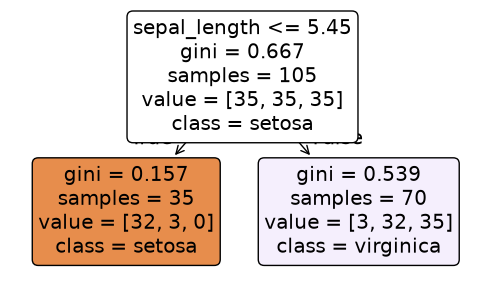

In [9]:
plt.figure(figsize=(6, 3.5))
plot_tree(pien, feature_names=cechy_2d, class_names=nazwy_klas, filled=True, rounded=True)
plt.show()

W węźle widzimy warunek podziału, `gini`, liczbę obserwacji (`samples`), liczności klas (`value`) i klasę większościową. Dodajmy kolejne poziomy i zobaczmy, jak zmieniają się granice oraz trafność na zbiorze treningowym i testowym:

/Users/tomasz/0.Szkolenia/ML_DL_Python [do przygotowania - potem zrobić z tego szablon na koniec]/.venv/lib/python3.13/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/Users/tomasz/0.Szkolenia/ML_DL_Python [do przygotowania - potem zrobić z tego szablon na koniec]/.venv/lib/python3.13/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/Users/tomasz/0.Szkolenia/ML_DL_Python [do przygotowania - potem zrobić z tego szablon na koniec]/.venv/lib/python3.13/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/Users/tomasz/0.Szkolenia/ML_DL_Python [do przygotowania - potem zrobić z tego szablon na koniec]/.venv/lib/python3.13/site-packages

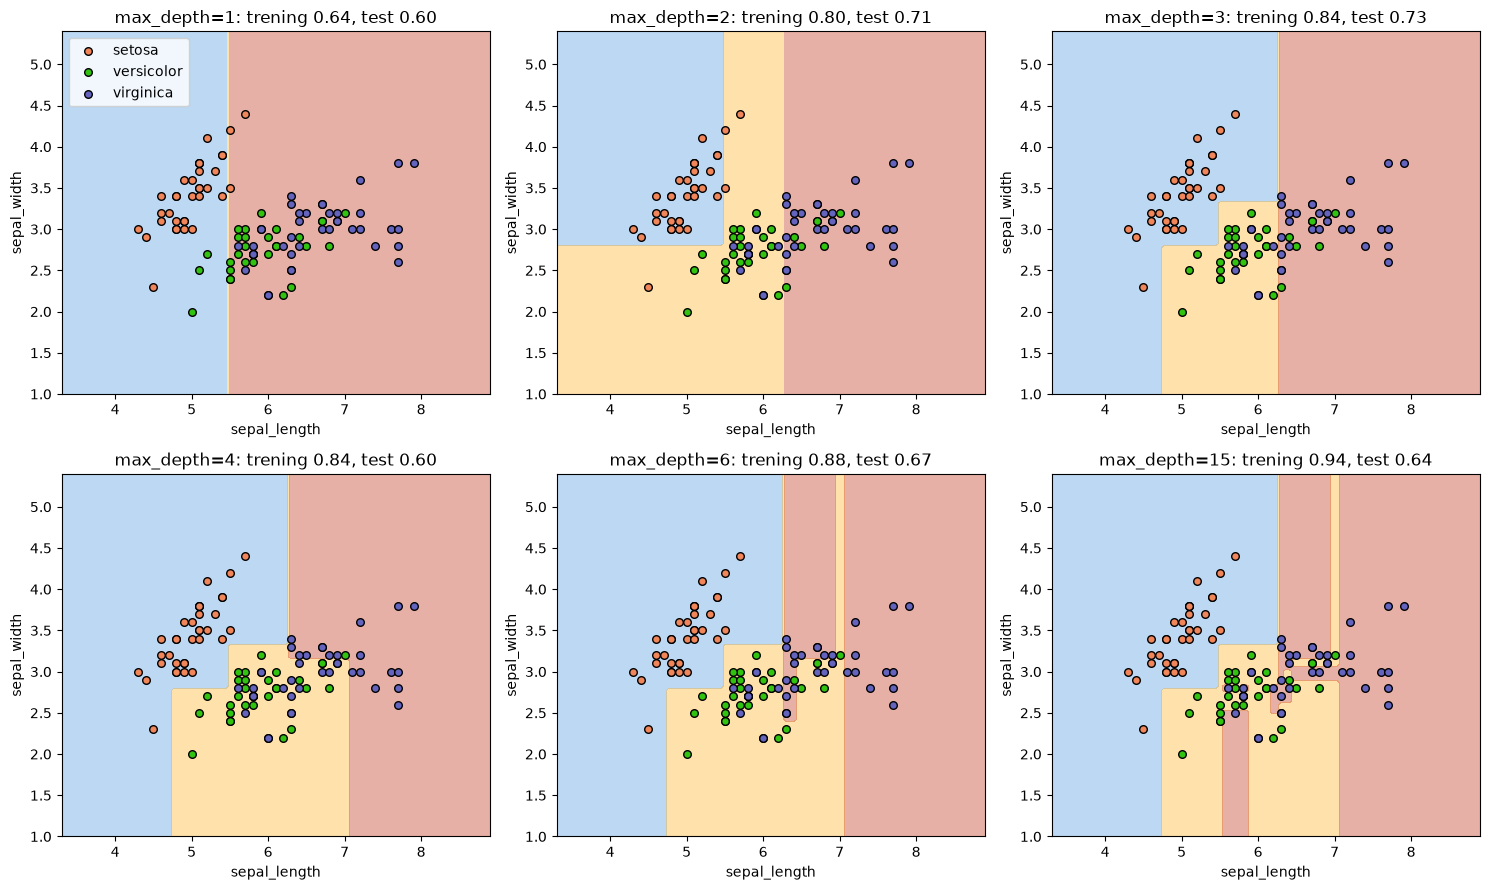

,max_depth,liczba liści,accuracy trening,accuracy test
0,1,2,0.638,0.600
1,2,4,0.800,0.711
2,3,7,0.838,0.733
3,4,9,0.838,0.600
4,6,15,0.876,0.667
5,15,33,0.943,0.644


In [10]:
glebokosci = [1, 2, 3, 4, 6, 15]
wyniki = []

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, glebokosc in zip(axes.ravel(), glebokosci):
    model = DecisionTreeClassifier(max_depth=glebokosc, random_state=42).fit(X_train, y_train)
    acc_train, acc_test = model.score(X_train, y_train), model.score(X_test, y_test)
    wyniki.append({'max_depth': glebokosc, 'liczba liści': model.get_n_leaves(),
                   'accuracy trening': round(acc_train, 3), 'accuracy test': round(acc_test, 3)})
    rysuj_granice(model, X_train, y_train, ax, f'max_depth={glebokosc}: trening {acc_train:.2f}, test {acc_test:.2f}')
axes[0, 0].legend(loc='upper left')
plt.tight_layout()
plt.show()

pd.DataFrame(wyniki)

**Wnioski:**
- Im głębsze drzewo, tym **więcej małych prostokątów** i tym lepsze dopasowanie do danych treningowych (trafność treningowa rośnie z 0,64 do 0,94).
- Trafność na zbiorze **testowym** najwyżej jest przy `max_depth=3` (ok. 0,73), a potem **spada** – drzewo uczy się szumu i przypadkowych punktów, a nie ogólnej reguły. To **przeuczenie (overfitting)**: duża różnica między wynikiem treningowym a testowym.
- Granice są zawsze **prostopadłe do osi** – tak działają podziały „cecha ≤ próg”.

Dobór głębokości (kompromis między niedouczeniem a przeuczeniem) omówimy w rozdziale 4.3.

## 4. Drzewo na wszystkich cechach

Dwie cechy kielicha dały średni wynik. Użyjmy wszystkich czterech, w tym wymiarów płatka.

In [11]:
cechy = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
X = df[cechy]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

print(f'Accuracy trening: {model.score(X_train, y_train):.3f}')
print(f'Accuracy test:    {model.score(X_test, y_test):.3f}')

Accuracy trening: 0.981
Accuracy test:    0.978


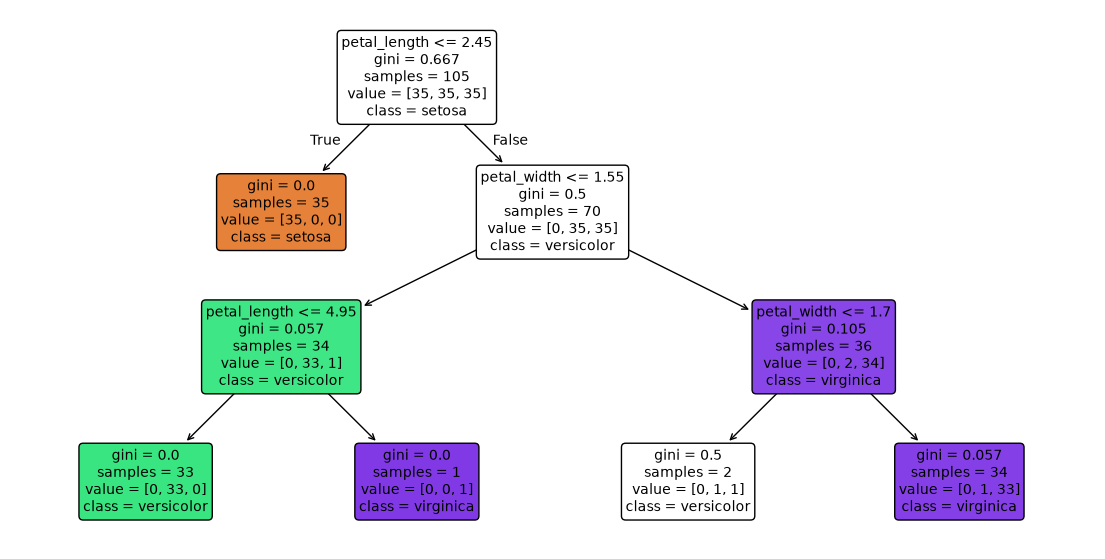

In [12]:
plt.figure(figsize=(14, 7))
plot_tree(model, feature_names=cechy, class_names=nazwy_klas, filled=True, rounded=True, fontsize=10)
plt.show()

Drzewo można też zapisać **jako tekst z regułami**, co jest wygodne do raportów i dokumentacji:

In [13]:
print(export_text(model, feature_names=cechy))

|--- petal_length <= 2.45
|   |--- class: 0
|--- petal_length >  2.45
|   |--- petal_width <= 1.55
|   |   |--- petal_length <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal_length >  4.95
|   |   |   |--- class: 2
|   |--- petal_width >  1.55
|   |   |--- petal_width <= 1.70
|   |   |   |--- class: 1
|   |   |--- petal_width >  1.70
|   |   |   |--- class: 2



Wystarczą dwie cechy płatka, aby bardzo dobrze rozdzielić gatunki. Potwierdza to ranking **ważności cech** (`feature_importances_`) – im większa wartość, tym więcej nieczystości zmniejszyły podziały na tej cesze (wartości sumują się do 1):

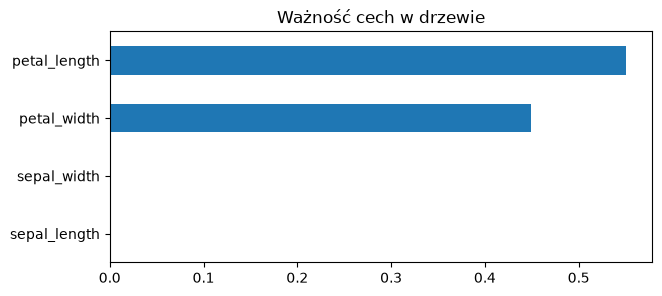

In [14]:
waznosc = pd.Series(model.feature_importances_, index=cechy).sort_values()
waznosc.plot.barh(figsize=(7, 3), title='Ważność cech w drzewie')
plt.show()

## 5. Predykcja dla nowego kwiatu

Nowy obiekt podajemy w takiej samej postaci jak dane treningowe (`DataFrame` z tymi samymi kolumnami). `predict_proba` zwraca **udziały klas w liściu**, do którego trafił kwiat.

In [15]:
nowy_kwiat = pd.DataFrame({'sepal_length': [5.0], 'sepal_width': [3.4], 'petal_length': [1.5], 'petal_width': [0.2]})

klasa = model.predict(nowy_kwiat)[0]
print('Przewidywany gatunek:', nazwy_klas[klasa])
print('Udziały klas w liściu:', {nazwa: round(float(p), 3) for nazwa, p in zip(nazwy_klas, model.predict_proba(nowy_kwiat)[0])})

Przewidywany gatunek: setosa
Udziały klas w liściu: {np.str_('setosa'): 1.0, np.str_('versicolor'): 0.0, np.str_('virginica'): 0.0}


## 6. Podsumowanie

1. Na dwóch cechach kielicha drzewo słabo rozdziela gatunki; płatki (`petal_*`) niosą niemal całą informację.
2. Wraz ze wzrostem `max_depth` trafność **treningowa rośnie**, ale **testowa** nie – to przeuczenie.
3. Drzewo to czytelny zestaw reguł: można je narysować (`plot_tree`) lub wypisać jako tekst (`export_text`).
4. `feature_importances_` pokazuje, które cechy były najważniejsze.